In [3]:
# Prerequisites
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 300
plt.rcParams["figure.figsize"] = (12, 5)

## ToDo:

- find severall blob shaping functions
    - mimic them
    - understand them
    - store source!
- figure out which one works best for our purposes
- ask someone else (Sina, Jakob)
- implement as shape method
- write tests
- write tutorial

### Idea 1

Source: https://gamedev.stackexchange.com/questions/62613/need-ideas-for-an-algorithm-to-draw-irregular-blotchy-shapes

Draw the outlines around a central point using polar coordinates:
$$ r=1+w_1*sin(\theta+\theta_1)+w_2*sin(2\theta+\theta_2)+w_3*sin(3\theta+\theta_3) + ...$$ 

In [4]:
import numpy as np

def term(x, i, w, theta):
    return w*np.sin(i*x + theta)

def funny_curve(x, I):
    res = 1
    for i in range(1, I+1):
        w = np.random.uniform(0.1, 1.0)
        theta = np.random.uniform(0, 2*np.pi)
        #print(f"i: {i}, w: {w}, theta: {theta}")
        res += term(x, i, w, theta)
    return res

funny_curve(1, 1)

np.float64(0.18279579170416127)

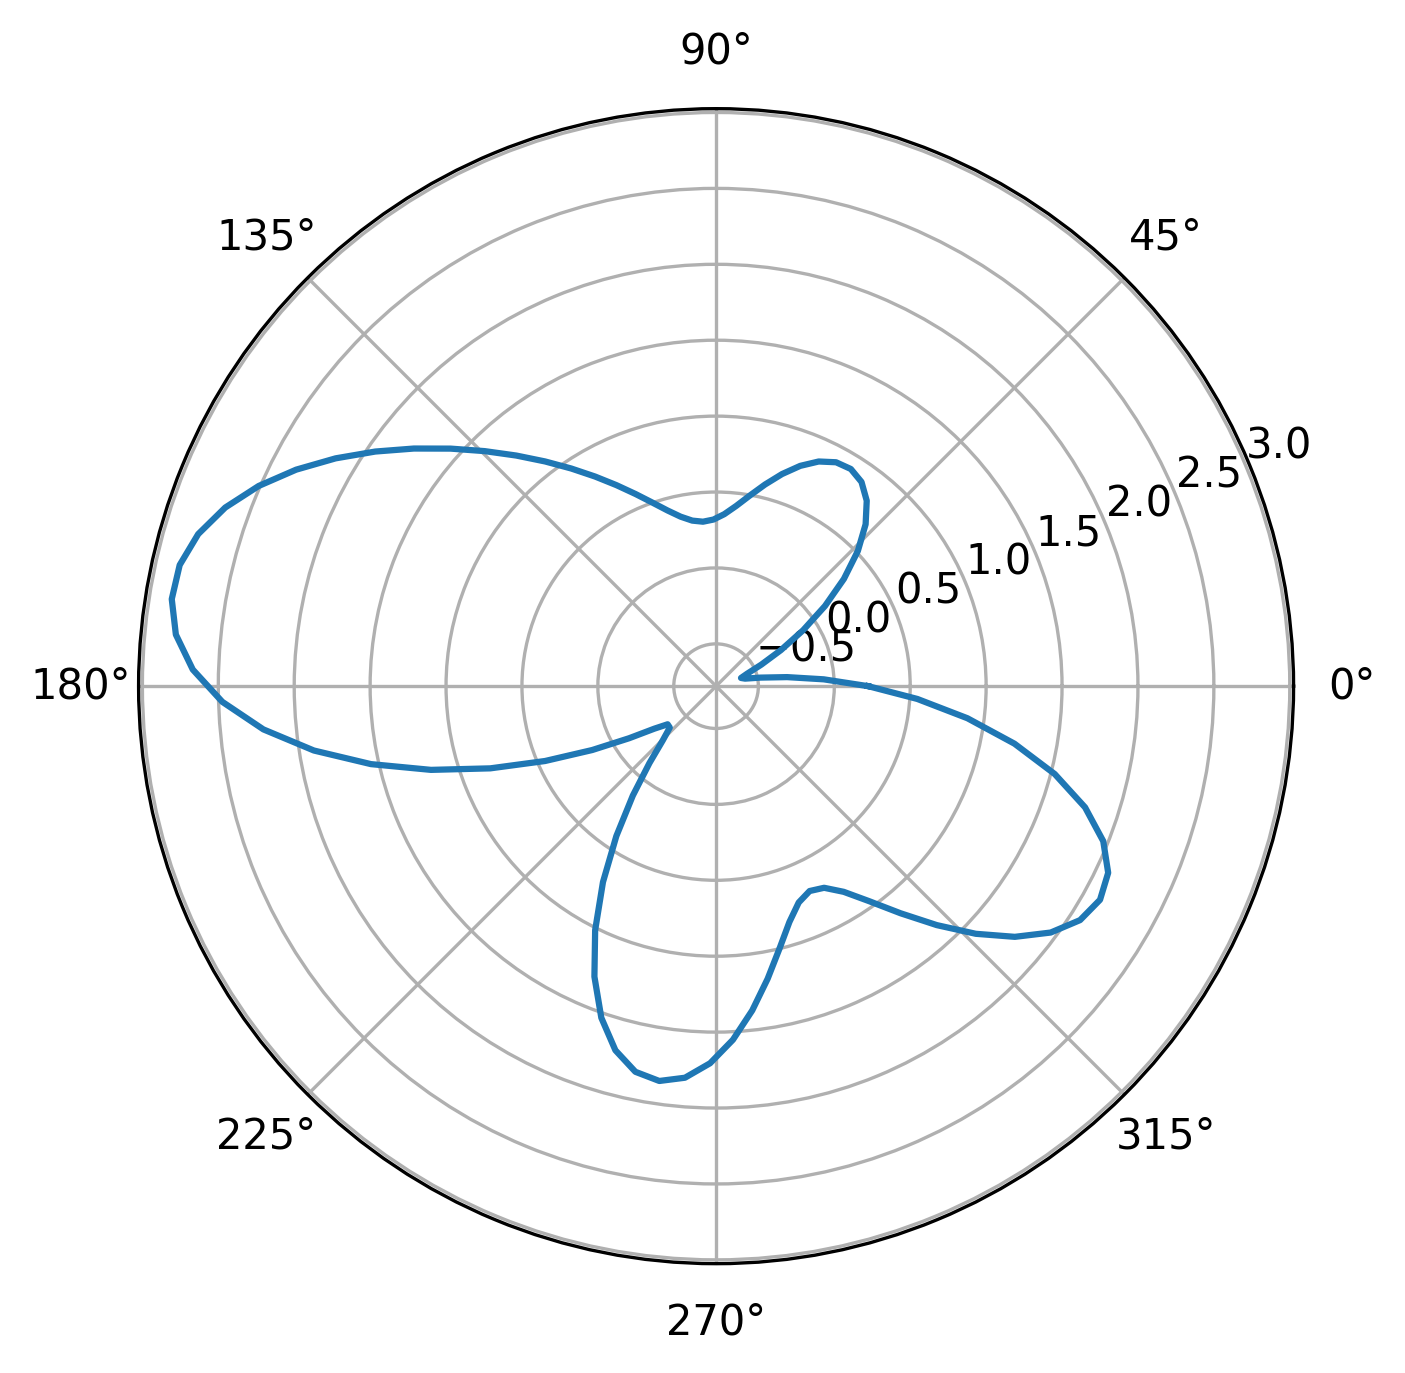

In [5]:
# plot in polar coordinates
import matplotlib.pyplot as plt
import numpy as np

theta = np.linspace(0, 2*np.pi, 100)
r = funny_curve(theta, 5)

plt.polar(theta, r)
plt.show()

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def term(x, i, w, theta):
    return w * np.sin(i * x + theta)

def funny_curve(angle, I, w_params, theta_params):
    res = np.ones_like(angle)
    for i in range(1, I + 1):
        res += term(angle, i, w_params[i - 1], theta_params[i - 1])
    return res

def make_shape(
    lats=np.linspace(-90, 90, 180),   # latitude grid
    lons=np.linspace(-180, 180, 360), # longitude grid
    max_radius=10.0,                  # angular radius in degrees
    center_lat=0.0,
    center_lon=0.0,
    random_seed=None,
    I=5,                              # number of sine terms
):
    if random_seed is not None:
        np.random.seed(random_seed)

    # Shape parameters
    w_params = []#np.random.uniform(min_radius, max_radius, size=I)
    for i in range(1,I+1):
        w = np.random.uniform(0, max_radius/(i))
        w_params.append(w)
    #print(f"w_params: {w_params}")
    theta_params = np.random.uniform(0, 2 * np.pi, size=I)
    #print(f"theta_params: {theta_params}")

    # Build lat/lon mesh
    Lon, Lat = np.meshgrid(lons, lats)

    # Compute offset from center (in degrees)
    dlat = Lat - center_lat
    dlon = Lon - center_lon

    # Adjust longitude difference for wrap-around
    dlon = (dlon + 180) % 360 - 180

    # Equirectangular approximation for distance in degrees
    # Account for longitude scaling with cos(lat_center)
    x = dlon * np.cos(np.radians(center_lat))
    y = dlat
    R = np.sqrt(x**2 + y**2)  # distance in degrees
    Theta = np.arctan2(y, x)  # angle in radians
    Theta[Theta < 0] += 2 * np.pi

    # Evaluate curve at each angle
    boundary_R = funny_curve(Theta, I, w_params, theta_params)

    # Scale boundary_R so that the maximum possible radius matches max_radius
    scale_factor = max_radius / np.max(boundary_R)
    boundary_R += scale_factor

    # Mask: inside if R <= boundary radius at that angle
    mask = (R <= boundary_R)

    return mask


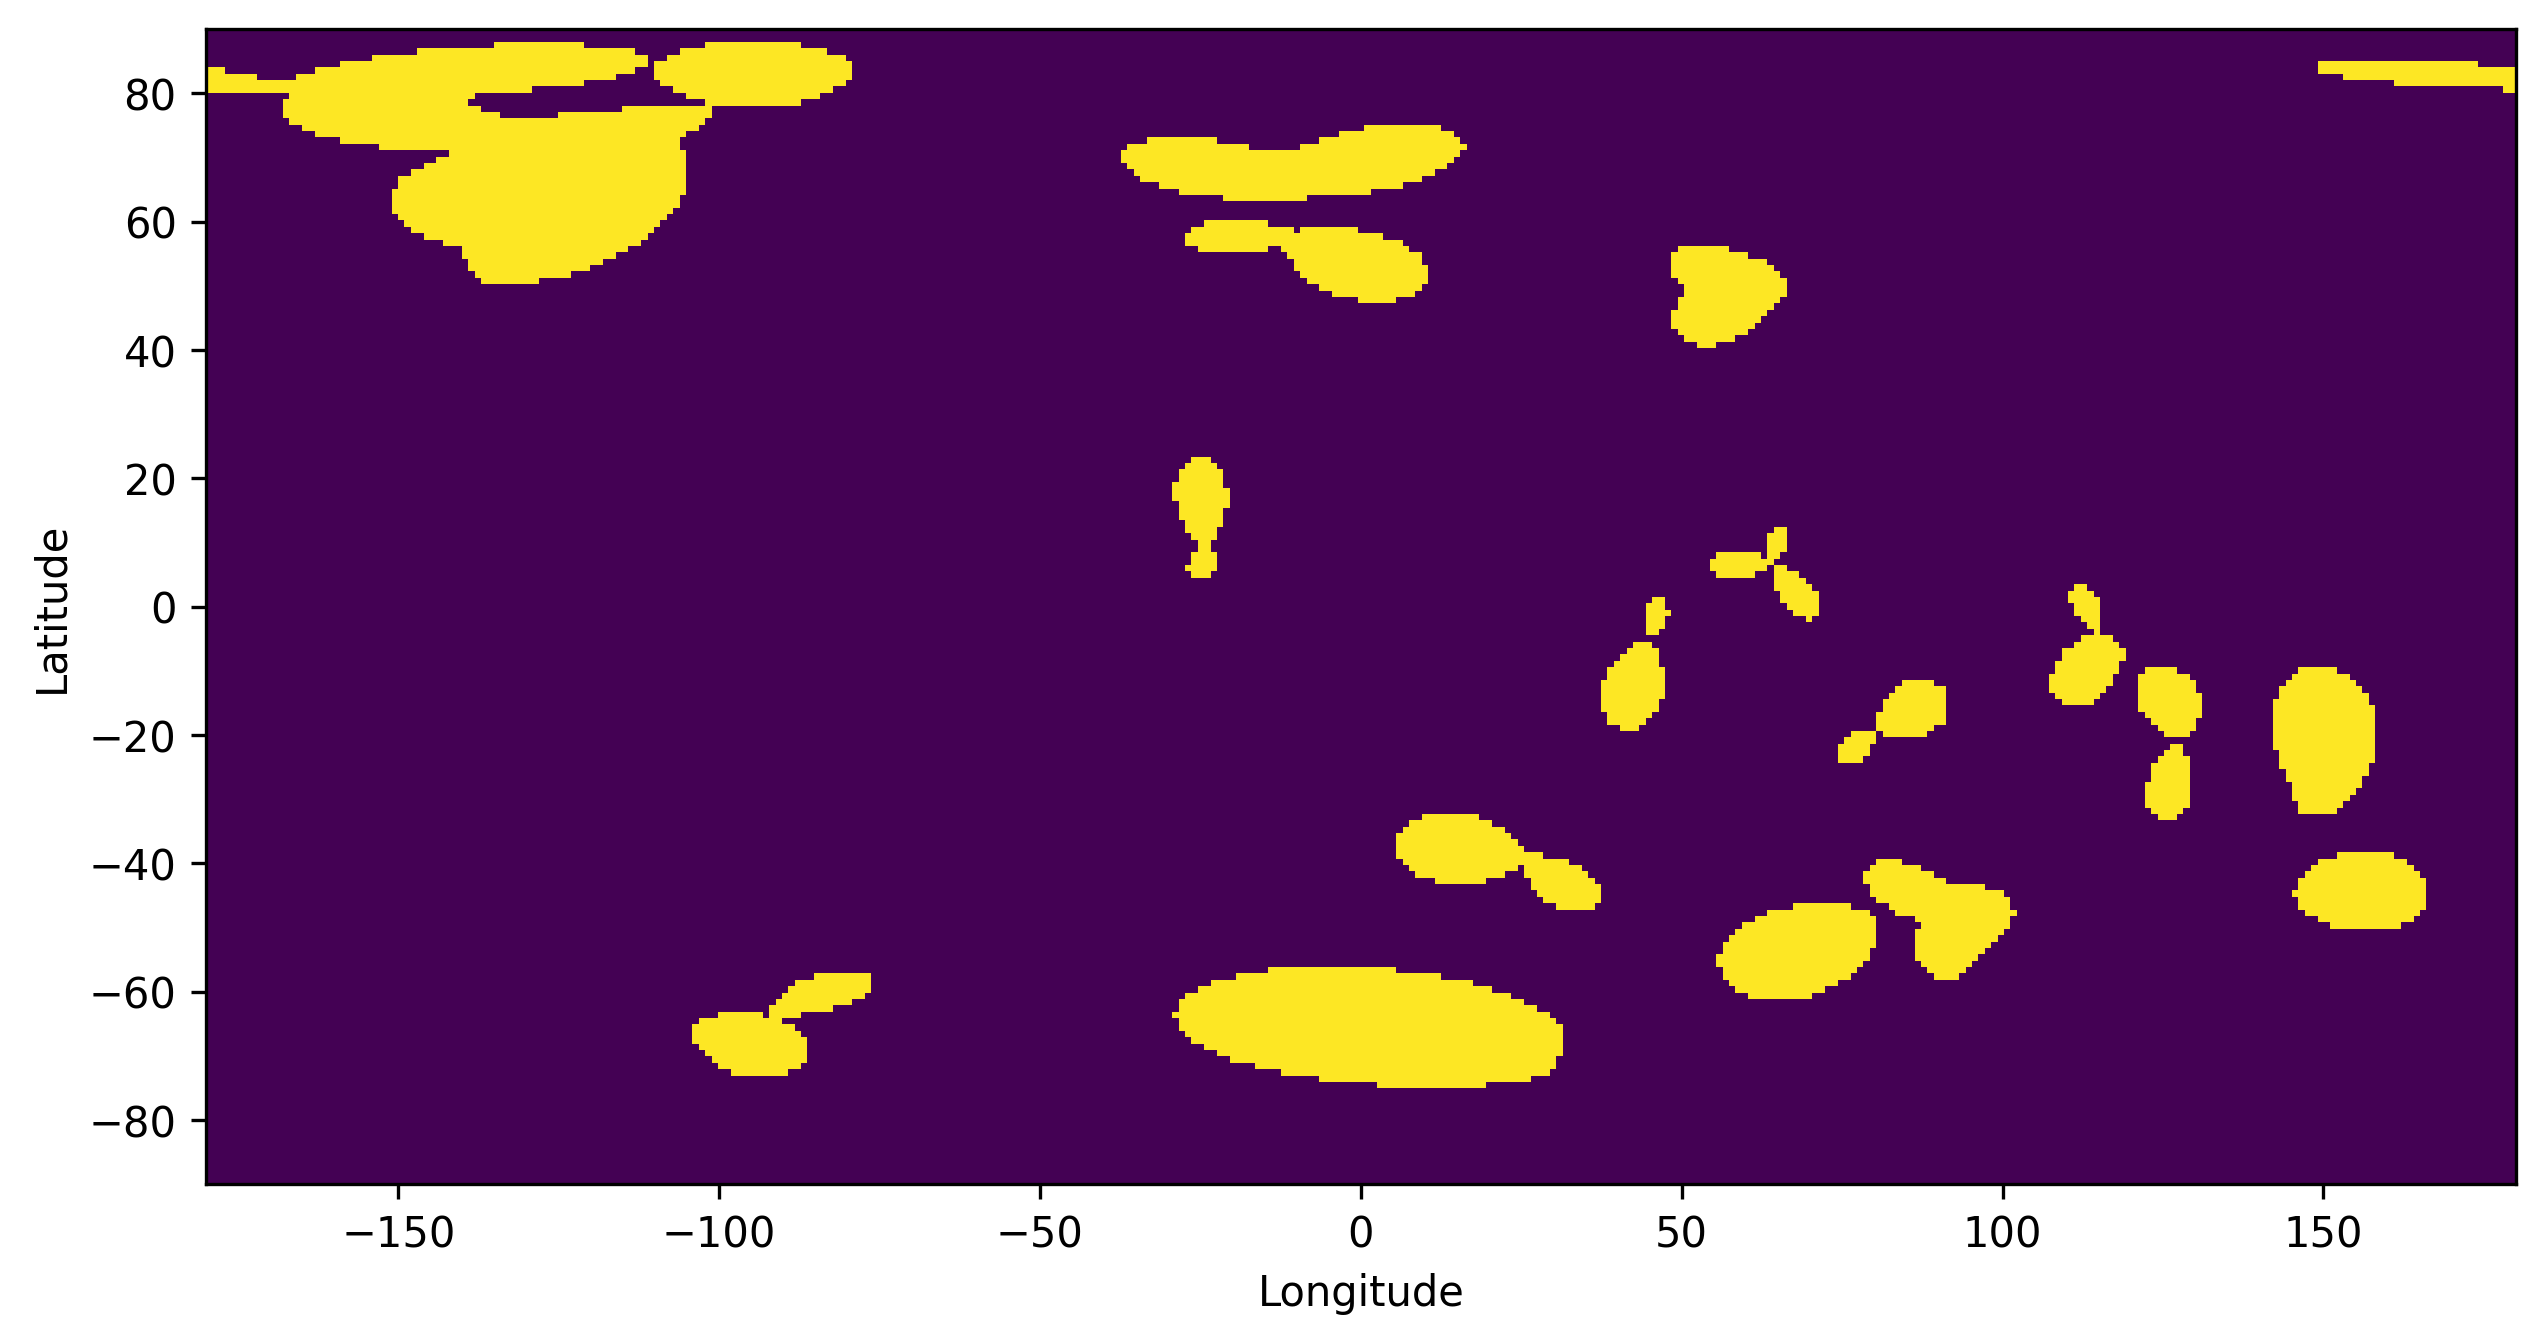

In [26]:
# --- Example usage ---
lat_extend = 90
lon_extend = 180
samples = 20

mask_tot = np.zeros((2*lat_extend + 1, 2*lon_extend + 1), dtype=bool)
for _ in range(samples):
    center_lat = np.random.uniform(-lat_extend, lat_extend)
    center_lon = np.random.uniform(-lon_extend, lon_extend)

    mask = make_shape(
        lats=np.linspace(-lat_extend, lat_extend, 2*lat_extend + 1),
        lons=np.linspace(-lon_extend, lon_extend, 2*lon_extend + 1),
        max_radius=lon_extend/10,  # Use lon_extend as max_radius
        center_lat=center_lat,
        center_lon=center_lon,
        I=3,
        random_seed=None,  # Set to None for random parameters
    )

    mask_tot |= mask

plt.figure(figsize=(12, 5))
plt.imshow(mask_tot, extent=(-lon_extend, lon_extend, -lat_extend, lat_extend),
            origin='lower', cmap='viridis')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()